In [ ]:
import numpy as np

# Modul sis (ako nije instaliran, npr. u Google Colab-u, instalira se automatski)
try:
    import sis
except ModuleNotFoundError:
    %pip install -q git+https://github.com/esokic/sis.git
    import sis

sis.FORMAT = "JUPYTER"    # prikaz grafika prilagodjen interaktivnom radu

In [2]:
# =========================================================
# Kod 6.1 - Napomena
# =========================================================

In [3]:
# FT i IFT (numericka aproksimacija Fourierove transformacije)
# se nalaze u sis modulu -> sis.FT, sis.IFT (koriste se od Kod 6.2).

def FT(x, t, w, ts):
    """Numericka aproksimacija Fourierove transformacije."""
    c = np.zeros(len(w), dtype=complex)
    for k, wk in enumerate(w):
        c[k] = ts * np.sum(x * np.exp(-1j * wk * t))
    return c


def IFT(F, w, t, ws):
    """Numericka aproksimacija inverzne Fourierove transformacije."""
    f = np.zeros(len(t), dtype=complex)
    for k, tk in enumerate(t):
        f[k] = ws / (2 * np.pi) * np.sum(F * np.exp(1j * w * tk))
    return f

In [4]:
# =========================================================
# Kod 6.2 - FT delta funkcije
# =========================================================

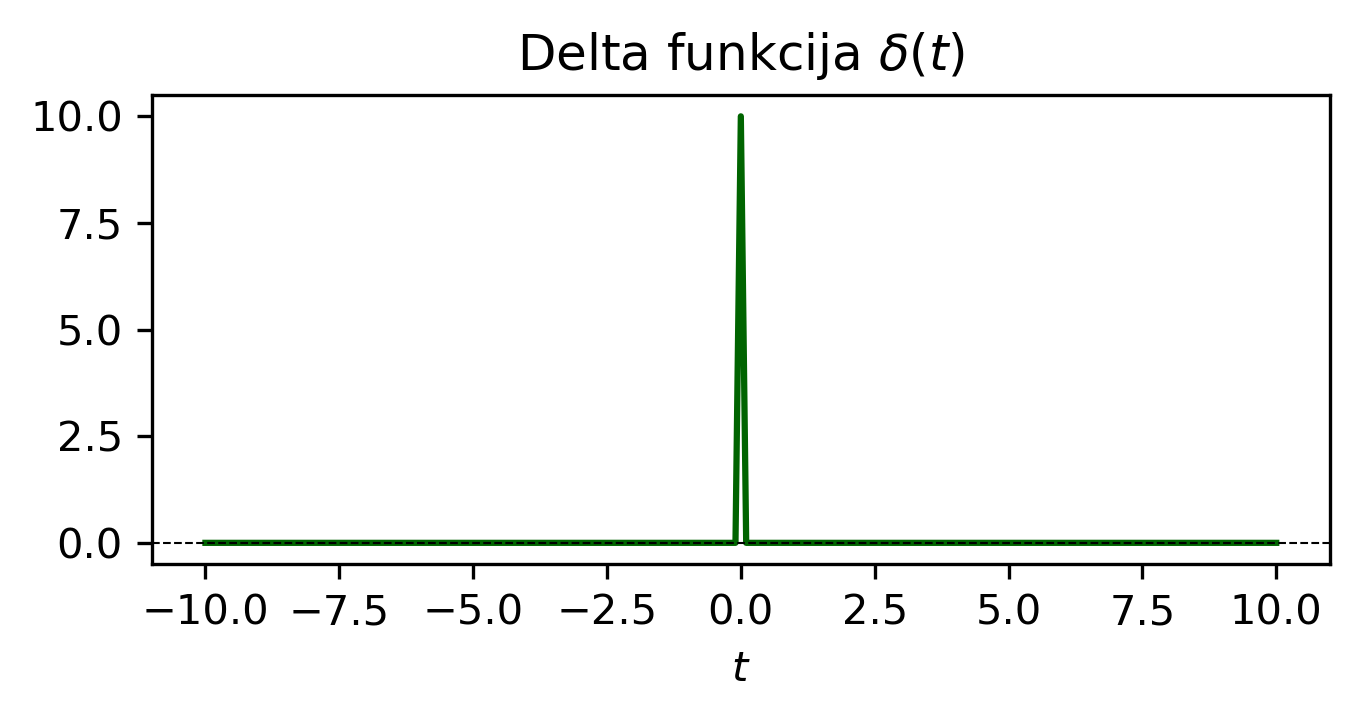

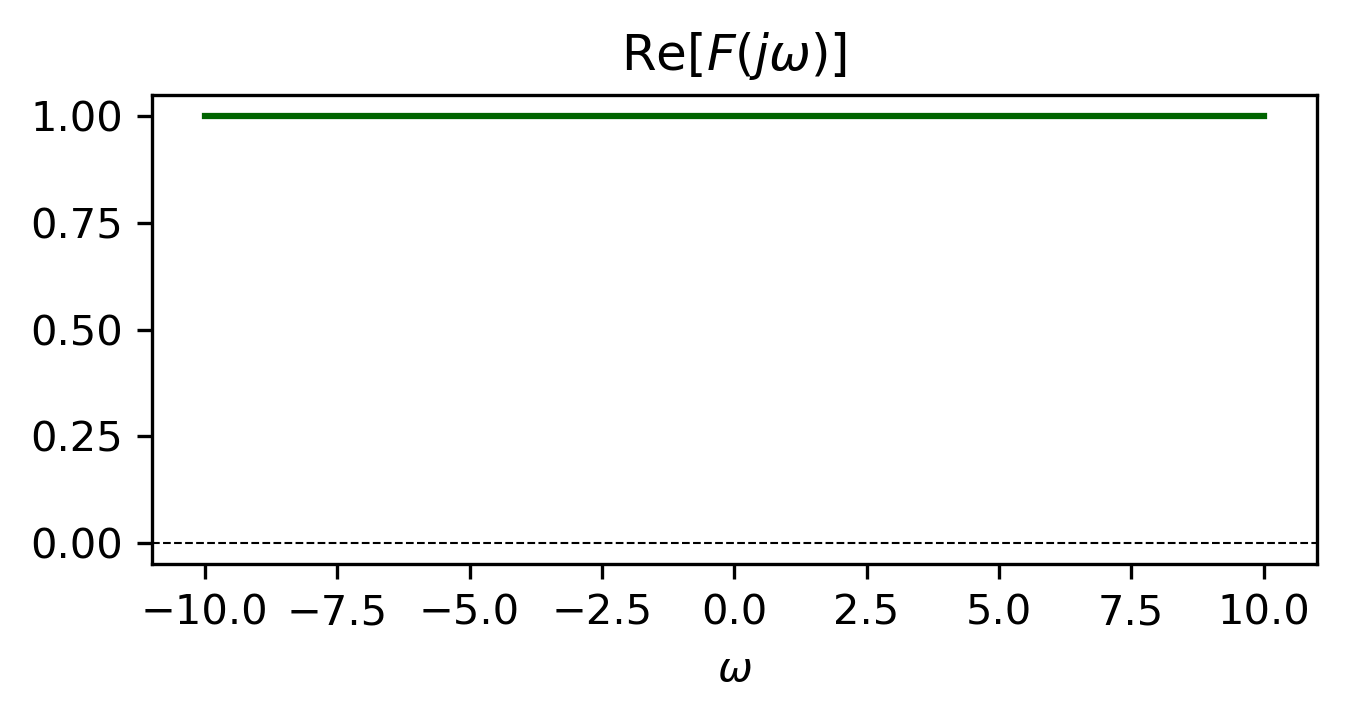

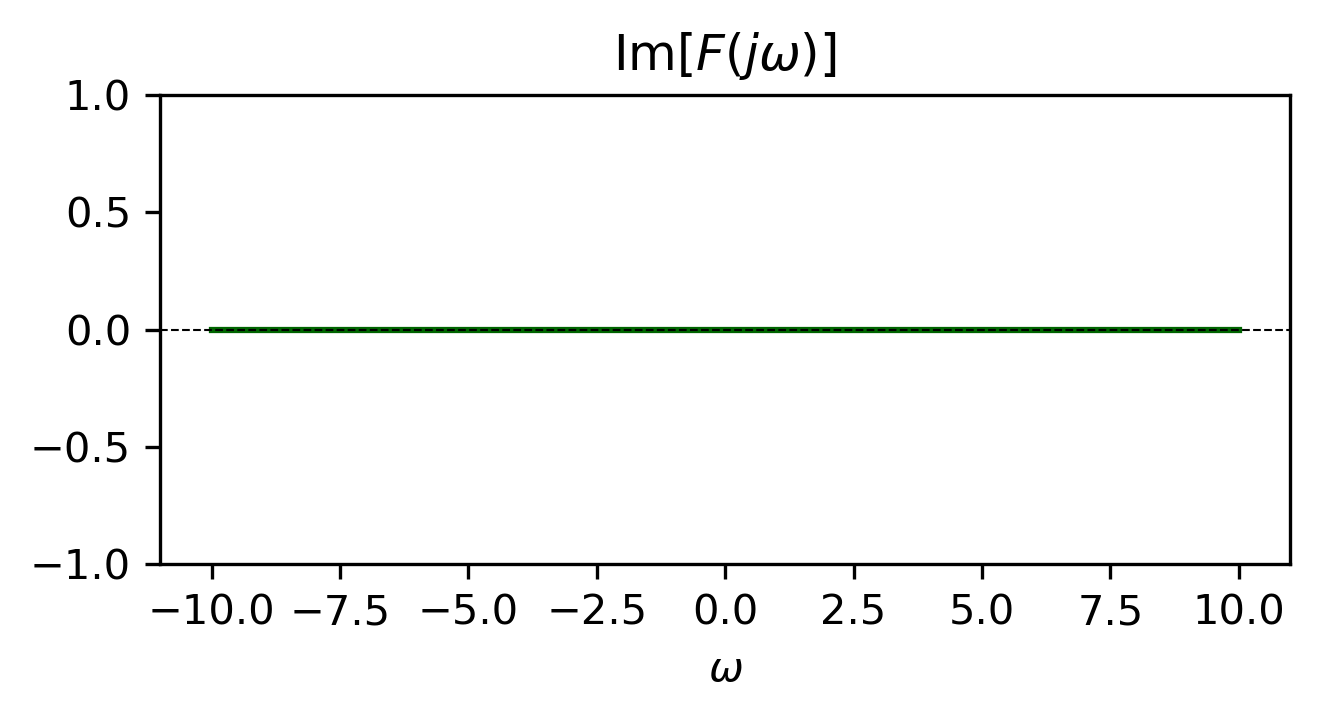

In [5]:
ts  = 0.1
ws  = 0.1
gra = 10
t = np.arange(-gra, gra + ts, ts)
w = np.arange(-gra, gra + ws, ws)

# delta funkcija: visina = 1/ts, centrirana u t=0
x = np.zeros(len(t))
idx0 = int((0 - (-gra)) / ts)
x[idx0] = 1/ts

C = sis.FT(x, t, w, ts)

sis.dijagram(t, x, 
              naslov=r'Delta funkcija $\delta(t)$'),
             
sis.dijagram(t, np.real(C),
             x_labela=r'$\omega$',
             naslov=r'$\mathrm{Re}[F(j\omega)]$')

sis.dijagram(w, np.imag(C), 
             x_labela=r'$\omega$',
             ylim=[-1,1], naslov=r'$\mathrm{Im}[F(j\omega)]$')

In [6]:
# =========================================================
# Kod 6.3 - FT funkcije Sa(at)
# =========================================================

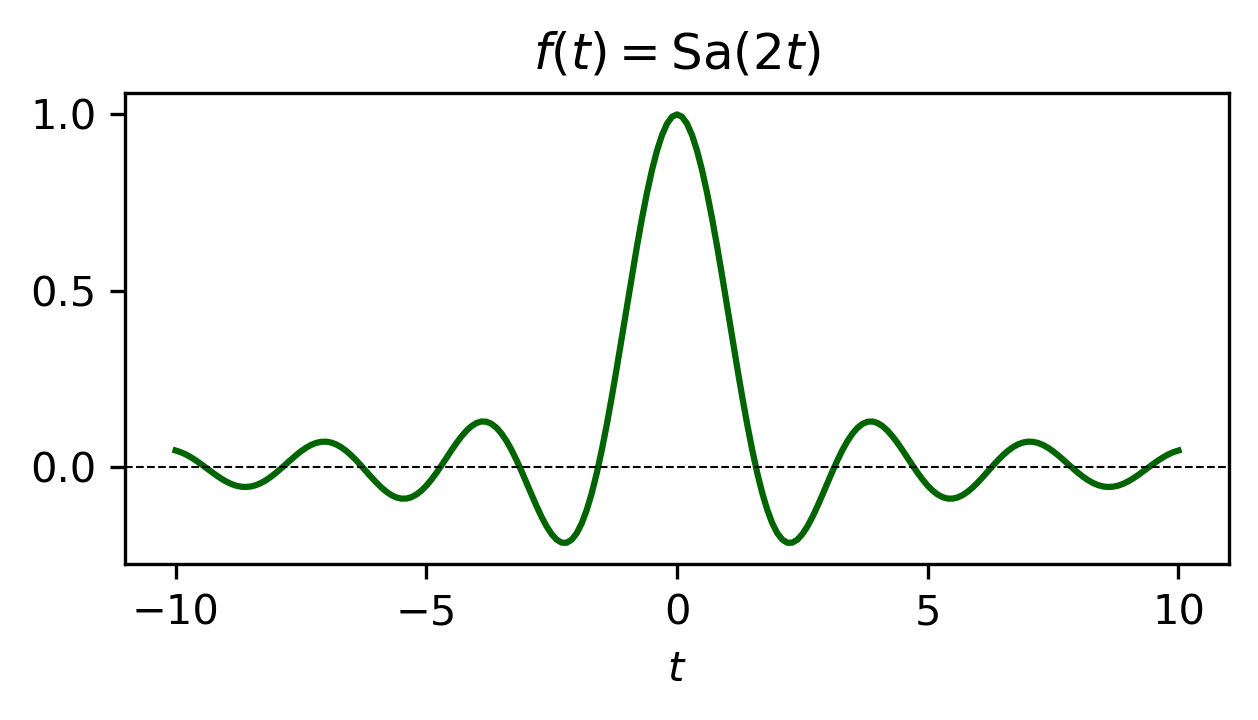

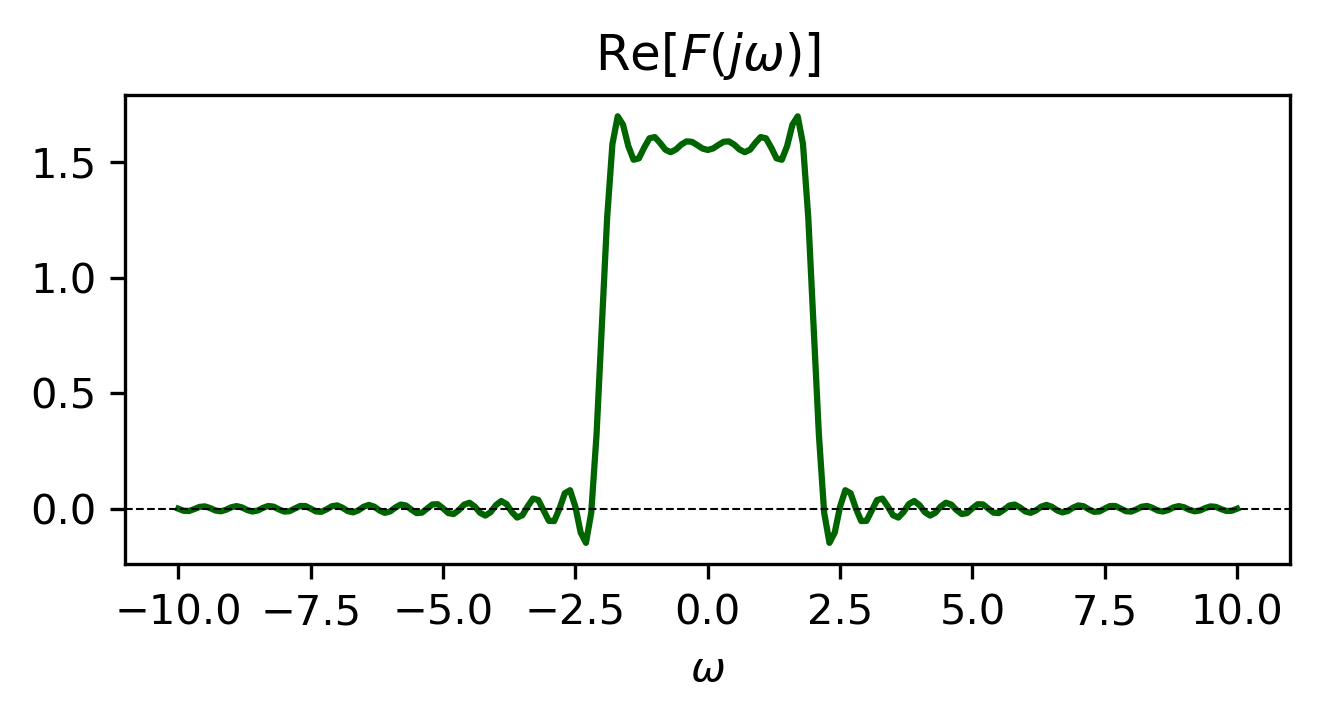

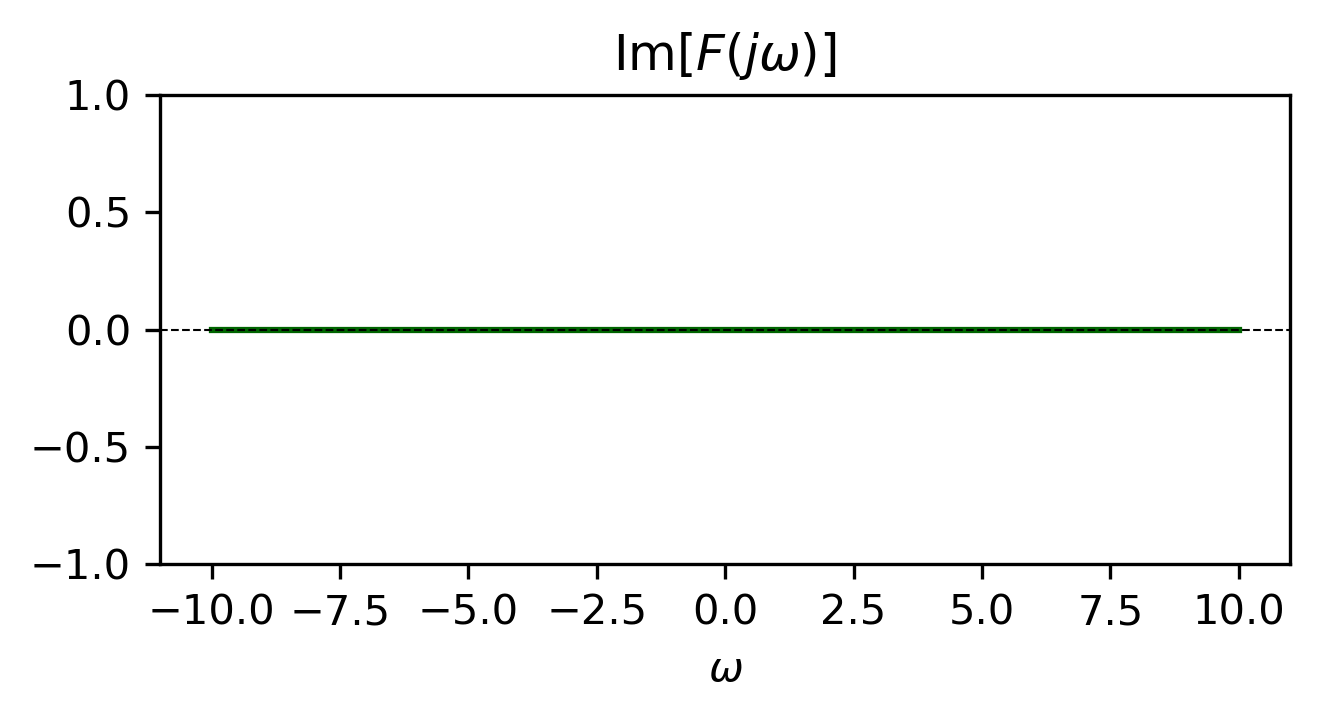

In [7]:
ts  = 0.1
ws  = 0.1
gra = 10

a   = 2
t = np.arange(-gra, gra + ts, ts)
w = np.arange(-gra, gra + ws, ws)

# Sa(at) = sinc(at/pi) u numpy konvenciji
x = np.sinc(a * t / np.pi)

C = sis.FT(x, t, w, ts)
 

sis.dijagram(t, x, 
              naslov=r'$f(t)=\mathrm{Sa}(2t)$'),
             
sis.dijagram(t, np.real(C),
             x_labela=r'$\omega$',
             naslov=r'$\mathrm{Re}[F(j\omega)]$')

sis.dijagram(w, np.imag(C), 
             x_labela=r'$\omega$',
             ylim=[-1,1], naslov=r'$\mathrm{Im}[F(j\omega)]$')

In [8]:
# =========================================================
# Kod 6.4 - FT funkcije p(t/a)
# =========================================================

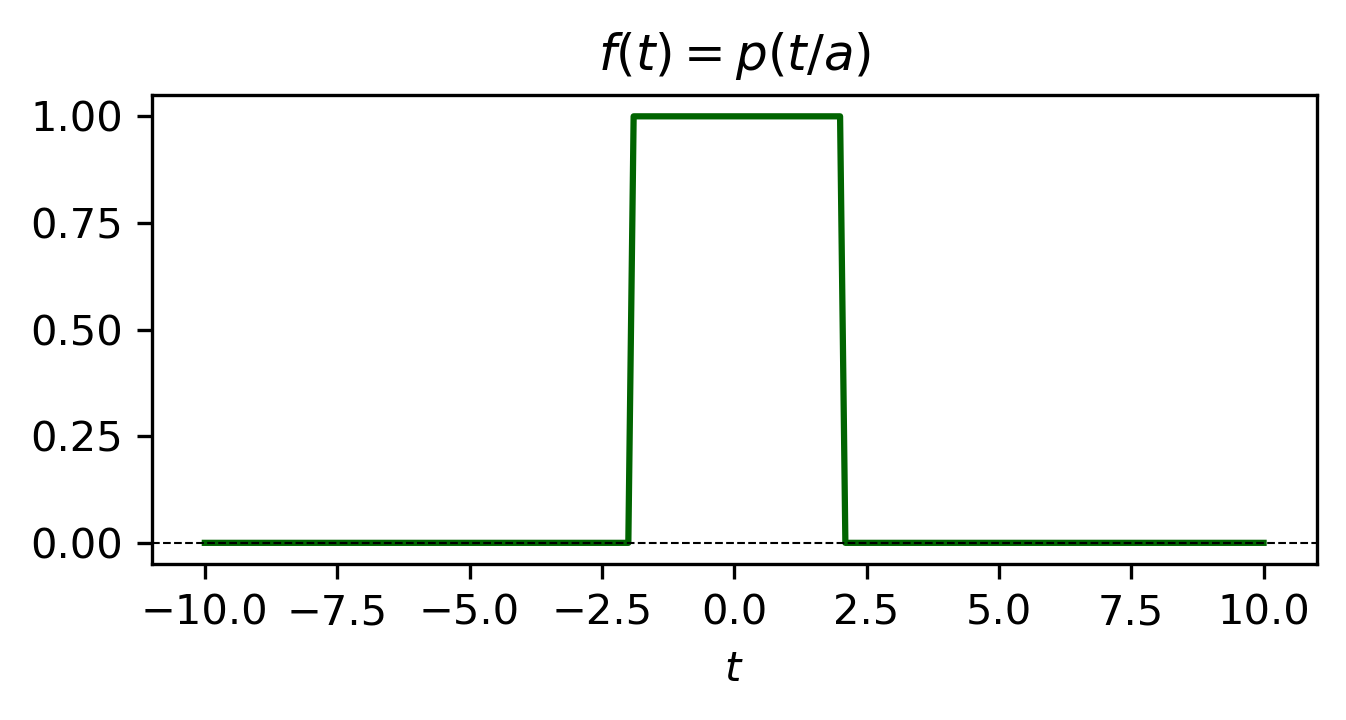

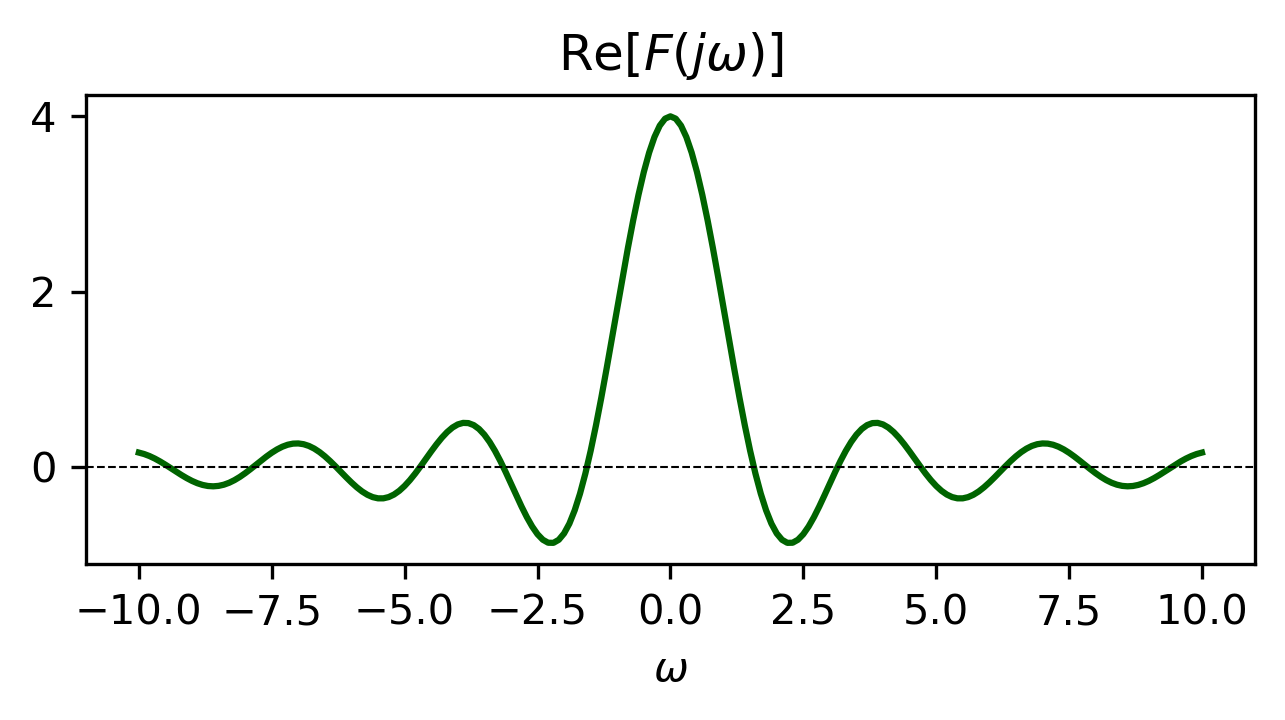

In [9]:
ts  = 0.1
ws  = 0.1
gra = 10

a   = 4
t = np.arange(-gra, gra + ts, ts)
w = np.arange(-gra, gra + ws, ws)

# p(t/a): pravougaoni impuls sirine a, centriran u t=0
x = np.zeros(len(t))
x[(t>=-a/2) & (t<=a/2)] = 1

C = sis.FT(x, t, w, ts)

sis.dijagram(t, x, 
            naslov=r'$f(t)=p(t/a)$'),
             
sis.dijagram(t, np.real(C),
             x_labela=r'$\omega$',
             naslov=r'$\mathrm{Re}[F(j\omega)]$')

In [10]:
# =========================================================
# Kod 6.5 - Inverzna FT: konvolucija dva pravougaona signala
# =========================================================

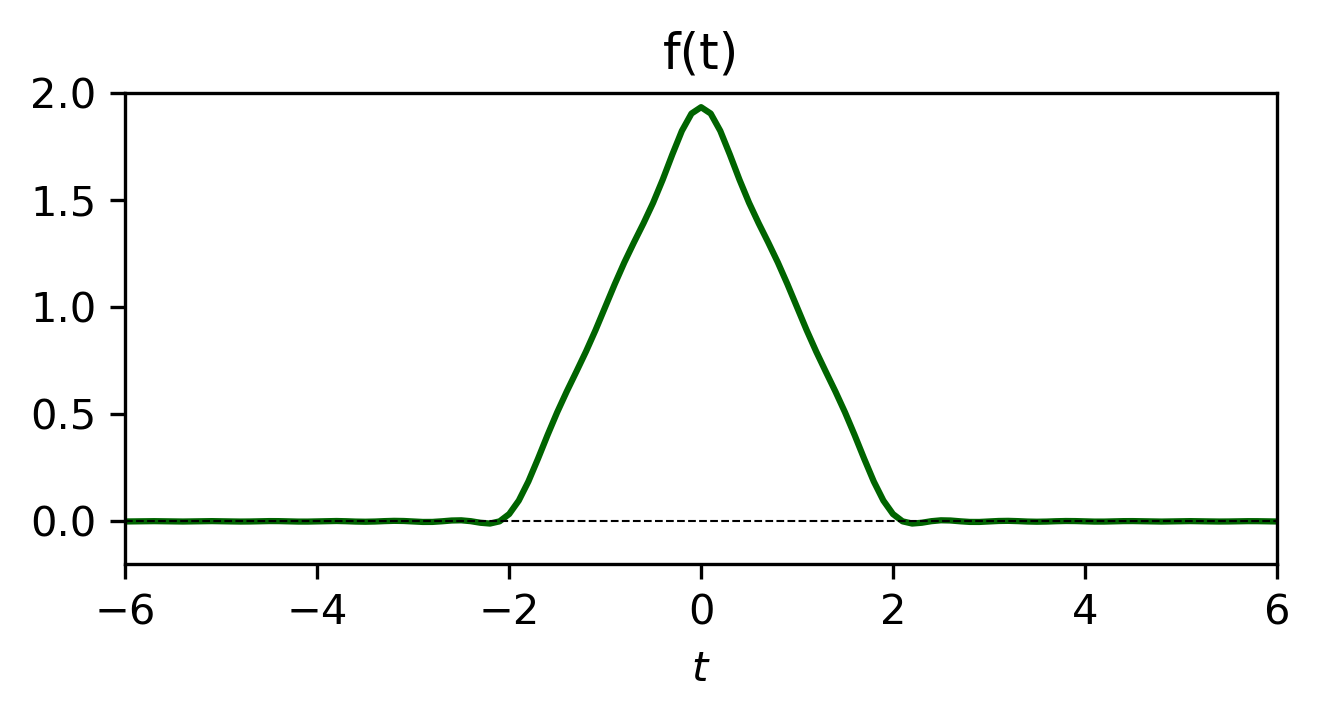

In [11]:
ts  = 0.1
ws  = 0.1
gra = 10
t = np.arange(-gra, gra + ts, ts)
w = np.arange(-gra, gra + ws, ws)

X = 2 * np.sinc(w / np.pi)
Y = 2 * np.sinc(w / np.pi)
Z = X * Y    # konvolucija u vremenu = mnozenje u frekventnom domenu

f = sis.IFT(Z, w, t, ws)

sis.dijagram(t, np.real(f), naslov='f(t)', ylim=(-.2, 2), xlim=(-6, 6))